# CDS 2413 – Programming for Data Analytics
## Project Deliverable 1 (CLO1 & CLO2) — Medical Cost Personal Dataset

**Dataset:** Medical Cost Personal Datasets (`insurance.csv`) — Kaggle
**Records:** 1,338 &nbsp;|&nbsp; **Columns:** `age`, `sex`, `bmi`, `children`, `smoker`, `region`, `charges`

> Place `insurance.csv` in the same folder as this notebook before running.

---
# CLO1 — Planning the Analysis

### Task 1: Purpose of the data analysis
The purpose of this analysis is to understand **what drives individual medical insurance charges** and to
**predict the charges** a person will be billed based on their personal attributes.

Specifically, we want to:
- Summarise how medical charges are distributed across the 1,338 policyholders (average cost, spread, skewness, outliers).
- Find which factors (age, BMI, smoking status, number of children, sex, region) are related to higher charges.
- Test statistical assumptions (correlation, independence, representativeness of samples).
- Build a foundation for a regression model (Deliverable 2) that an insurance company could use to set fair premiums,
  and that individuals could use to understand how lifestyle choices (e.g. smoking, BMI) affect their healthcare costs.

### Task 2: Type of programming used — and why
We use **Python** with a combination of **procedural** and **functional / modular programming** inside a **Jupyter Notebook**:
- **Procedural:** the analysis runs step-by-step (load → sample → describe → visualise → test), which mirrors the data-analysis workflow.
- **Modular / functional:** reusable functions (e.g. `descriptive_stats(sample, field)`, `systematic_sample(...)`) are written once and applied to the
  population, the random sample and the systematic sample, avoiding repeated code.
- **Object-oriented libraries:** we use objects from pandas (`DataFrame`), matplotlib/seaborn (figures) and SciPy.

**Justification:** Python is free, open-source and the industry standard for data analytics. Its libraries cover every stage of this project —
`pandas`/`numpy` (data handling), `matplotlib`/`seaborn` (visualisation), `scipy.stats` (hypothesis testing) and `scikit-learn` (machine learning in D2).
Jupyter lets us combine code, output and explanation in one reproducible report.

### Task 3: Type and purpose of the Machine Learning algorithm
- **Type:** **Supervised learning — Regression.** The target `charges` is a **continuous numeric** value, and the dataset is labelled (we know the charges for every person),
  so supervised regression is the correct family.
- **Algorithms:** **Simple Linear Regression** (one predictor, e.g. `age` → `charges`) and **Multiple Linear Regression** (all relevant predictors → `charges`).
- **Purpose:** to model the relationship between personal attributes and medical charges and to **predict the expected charges for a new person**.
- For the later CLO3 tasks, `charges` can also be converted into classes (e.g. *High* / *Low* cost) for **classification**
  (Logistic Regression, KNN, Naïve Bayes, Decision Tree), and **clustering** (K-Means, Hierarchical — unsupervised) can group customers with similar profiles.

### Task 4: Independent and dependent variables
| Variable | Type | Role | Justification |
|---|---|---|---|
| `charges` | Numeric (continuous) | **Dependent (target, Y)** | It is the outcome we want to explain and predict — the medical cost billed by insurance. It depends on the person's characteristics. |
| `age` | Numeric (discrete) | Independent (X) | Older people generally need more medical care. |
| `bmi` | Numeric (continuous) | Independent (X) | High BMI (obesity) is linked to chronic diseases and higher costs. |
| `children` | Numeric (discrete) | Independent (X) | Number of dependents covered by the plan. |
| `smoker` | Categorical (yes/no) | Independent (X) | Smoking is a major health risk factor — expected to be the strongest driver of charges. |
| `sex` | Categorical (male/female) | Independent (X) | Possible differences in healthcare usage. |
| `region` | Categorical (4 regions) | Independent (X) | Healthcare prices may differ by US region. |

The independent variables are attributes of the person that exist **before** the bill; `charges` is the **result**, so it is the dependent variable.

---
# CLO2 — Descriptive Analysis, Sampling, Visualisation & Hypothesis Testing

## Setup: import libraries and load the dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mirichoi0218/insurance")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Zain Faisal\.cache\kagglehub\datasets\mirichoi0218\insurance\versions\1


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_style('whitegrid')

df = pd.read_csv(os.path.join(path, 'insurance.csv'))
print('Shape:', df.shape)
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
# Data quality checks
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.5900,0,no,northwest,"1,639.5631"
581,19,male,30.5900,0,no,northwest,"1,639.5631"


In [5]:
# Remove the duplicate record so it does not bias the statistics
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)
df.describe(include='all')

Shape after removing duplicates: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
count,"1,337.0000",1337,"1,337.0000","1,337.0000",1337,1337,"1,337.0000"
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,675,NaN,NaN,1063,364,NaN
mean,39.2221,NaN,30.6635,1.0957,NaN,NaN,"13,279.1215"
std,14.0443,NaN,6.1005,1.2056,NaN,NaN,"12,110.3597"
min,18.0000,NaN,15.9600,0.0000,NaN,NaN,"1,121.8739"
25%,27.0000,NaN,26.2900,0.0000,NaN,NaN,"4,746.3440"
50%,39.0000,NaN,30.4000,1.0000,NaN,NaN,"9,386.1613"
75%,51.0000,NaN,34.7000,2.0000,NaN,NaN,"16,657.7175"


## Task 5: Why perform descriptive analysis on this dataset?
Descriptive analysis is the first step before any modelling because it:
1. **Summarises the dependent variable `charges`** — its centre (mean, median), spread (std, variance, range, IQR) and shape (skewness, kurtosis).
2. **Reveals the distribution shape** — medical charges are expected to be right-skewed (a few very expensive patients), which affects model choice and whether we should transform the data.
3. **Detects outliers and data-quality issues** (missing values, duplicates) that could distort a regression model.
4. **Allows comparison** between the population and samples, so we can check that our samples are representative.
5. **Guides hypothesis testing and feature selection** — e.g. a big difference in mean charges between smokers and non-smokers suggests `smoker` is a key predictor.

## Task 6: Python function for descriptive statistics
The function takes **the sample (DataFrame)** and **the field (column name)** as input, and returns a full set of descriptive statistics.

In [6]:
def descriptive_stats(sample, field):
    """
    Compute descriptive statistics for one numeric field of a sample.

    Parameters
    ----------
    sample : pandas.DataFrame  - the data (population or a sample)
    field  : str               - the column to describe

    Returns
    -------
    pandas.Series with the descriptive statistics
    """
    data = sample[field].dropna()
    n = data.count()
    mean = data.mean()
    std = data.std()                       # sample standard deviation (ddof=1)
    q1, q3 = data.quantile(0.25), data.quantile(0.75)

    result = {
        'Count': n,
        'Mean': mean,
        'Median': data.median(),
        'Mode': data.mode().iloc[0],
        'Standard Deviation': std,
        'Variance': data.var(),
        'Standard Error': std / np.sqrt(n),
        'Minimum': data.min(),
        'Maximum': data.max(),
        'Range': data.max() - data.min(),
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'IQR': q3 - q1,
        'Skewness': data.skew(),
        'Kurtosis': data.kurt(),
        'Coefficient of Variation (%)': std / mean * 100,
        'Sum': data.sum(),
    }
    return pd.Series(result, name=field)


# Test the function on the full dataset (population)
pop_stats = descriptive_stats(df, 'charges')
pop_stats.to_frame('Population – charges')

,Population – charges
Count,"1,337.0000"
Mean,"13,279.1215"
Median,"9,386.1613"
Mode,"1,121.8739"
Standard Deviation,"12,110.3597"
Variance,"146,660,811.0060"
Standard Error,331.2008
Minimum,"1,121.8739"
Maximum,"63,770.4280"
Range,"62,648.5541"


## Task 7: Random sampling (n = 150) and descriptive statistics of the dependent variable
Simple random sampling gives every record the same chance of being selected. `random_state=42` makes the result reproducible.

In [7]:
random_sample = df.sample(n=150, random_state=42)
print('Random sample size:', len(random_sample))
display(random_sample.head())

random_stats = descriptive_stats(random_sample, 'charges')
random_stats.to_frame('Random sample – charges')

Random sample size: 150


,age,sex,bmi,children,smoker,region,charges
899,49,male,22.5150,0,no,northeast,"8,688.8589"
1063,29,female,25.6000,4,no,southwest,"5,708.8670"
1255,51,female,36.3850,3,no,northwest,"11,436.7381"
298,31,male,34.3900,3,yes,northwest,"38,746.3551"
237,31,male,38.3900,2,no,southeast,"4,463.2051"


,Random sample – charges
Count,150.0000
Mean,"13,960.7131"
Median,"9,404.5061"
Mode,"1,135.9407"
Standard Deviation,"13,627.7432"
Variance,"185,715,384.8183"
Standard Error,"1,112.7006"
Minimum,"1,135.9407"
Maximum,"63,770.4280"
Range,"62,634.4873"


## Task 8: Systematic sampling with conditions
**Conditions applied:** we focus on **adult policyholders aged 25 and above who have at least one child** (`age >= 25` and `children >= 1`) —
i.e. working-age parents, a key customer group for family insurance plans.

**Method:** from the filtered list, compute the sampling interval `k = N / n`, pick a random starting point between 0 and k−1,
and then select every *k*-th record.

In [8]:
def systematic_sample(data, n, condition=None, random_state=42):
    """
    Systematic sampling: select every k-th record after a random start.

    data      : DataFrame
    n         : desired sample size
    condition : boolean mask (optional) to filter the data first
    """
    population = data[condition] if condition is not None else data
    population = population.reset_index(drop=True)
    N = len(population)
    k = N // n                                        # sampling interval
    rng = np.random.default_rng(random_state)
    start = rng.integers(0, k)                        # random start in [0, k-1]
    indices = np.arange(start, start + k * n, k)      # start, start+k, start+2k, ...
    print(f'Filtered population N = {N}, sample size n = {n}, interval k = {k}, start = {start}')
    return population.iloc[indices]


condition = (df['age'] >= 25) & (df['children'] >= 1)
systematic = systematic_sample(df, n=150, condition=condition)
print('Systematic sample size:', len(systematic))
display(systematic.head())

systematic_stats = descriptive_stats(systematic, 'charges')
systematic_stats.to_frame('Systematic sample – charges')

Filtered population N = 674, sample size n = 150, interval k = 4, start = 0
Systematic sample size: 150


,age,sex,bmi,children,smoker,region,charges
0,28,male,33.0000,3,no,southeast,"4,449.4620"
4,52,female,30.7800,1,no,northeast,"10,797.3362"
8,59,female,27.7200,3,no,southeast,"14,001.1338"
12,62,female,32.9650,3,no,northwest,"15,612.1933"
16,37,female,30.8000,2,no,southeast,"6,313.7590"


,Systematic sample – charges
Count,150.0000
Mean,"14,225.5412"
Median,"9,236.1547"
Mode,"2,902.9065"
Standard Deviation,"11,928.0444"
Variance,"142,278,242.6516"
Standard Error,973.9207
Minimum,"2,902.9065"
Maximum,"58,571.0745"
Range,"55,668.1680"


## Task 9: Detailed descriptive statistics report — dependent variable `charges`
### 9.1 Population vs. random sample vs. systematic sample

In [9]:
report = pd.concat([pop_stats.rename('Population'),
                    random_stats.rename('Random Sample (n=150)'),
                    systematic_stats.rename('Systematic Sample (n=150)')], axis=1)
report

,Population,Random Sample (n=150),Systematic Sample (n=150)
Count,"1,337.0000",150.0000,150.0000
Mean,"13,279.1215","13,960.7131","14,225.5412"
Median,"9,386.1613","9,404.5061","9,236.1547"
Mode,"1,121.8739","1,135.9407","2,902.9065"
Standard Deviation,"12,110.3597","13,627.7432","11,928.0444"
Variance,"146,660,811.0060","185,715,384.8183","142,278,242.6516"
Standard Error,331.2008,"1,112.7006",973.9207
Minimum,"1,121.8739","1,135.9407","2,902.9065"
Maximum,"63,770.4280","63,770.4280","58,571.0745"
Range,"62,648.5541","62,634.4873","55,668.1680"


### 9.2 Charges broken down by the categorical independent variables

In [10]:
for col in ['smoker', 'sex', 'region']:
    print(f'\n===== charges by {col} =====')
    display(df.groupby(col)['charges'].agg(['count', 'mean', 'median', 'std', 'min', 'max']))


===== charges by smoker =====


,count,mean,median,std,min,max
smoker,,,,,,
no,1063,"8,440.6603","7,345.7266","5,992.9738","1,121.8739","36,910.6080"
yes,274,"32,050.2318","34,456.3485","11,541.5472","12,829.4551","63,770.4280"



===== charges by sex =====


,count,mean,median,std,min,max
sex,,,,,,
female,662,"12,569.5788","9,412.9625","11,128.7038","1,607.5101","63,770.4280"
male,675,"13,974.9989","9,377.9047","12,971.9587","1,121.8739","62,592.8731"



===== charges by region =====


,count,mean,median,std,min,max
region,,,,,,
northeast,324,"13,406.3845","10,057.6520","11,255.8031","1,694.7964","58,571.0745"
northwest,324,"12,450.8408","8,976.9772","11,073.1257","1,621.3402","60,021.3990"
southeast,364,"14,735.4114","9,294.1319","13,971.0986","1,121.8739","63,770.4280"
southwest,325,"12,346.9374","8,798.5930","11,557.1791","1,241.5650","52,590.8294"


### 9.3 Outlier detection (IQR method)

In [11]:
q1, q3 = df['charges'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df['charges'] < lower) | (df['charges'] > upper)]

print(f'Lower fence: {lower:,.2f}   Upper fence: {upper:,.2f}')
print(f'Number of outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% of records)')
print('\nSmoker share among outliers:')
print(outliers['smoker'].value_counts(normalize=True).round(3))

# Dataset without outliers (kept separately for comparison)
df_no_outliers = df[(df['charges'] >= lower) & (df['charges'] <= upper)]
print('\nShape without outliers:', df_no_outliers.shape)
descriptive_stats(df_no_outliers, 'charges').to_frame('Charges without outliers')

Lower fence: -13,120.72   Upper fence: 34,524.78
Number of outliers: 139 (10.4% of records)

Smoker share among outliers:
smoker
yes   0.9780
no    0.0220
Name: proportion, dtype: float64

Shape without outliers: (1198, 7)


,Charges without outliers
Count,"1,198.0000"
Mean,"9,934.6718"
Median,"8,411.7550"
Mode,"1,121.8739"
Standard Deviation,"7,240.2170"
Variance,"52,420,742.0165"
Standard Error,209.1815
Minimum,"1,121.8739"
Maximum,"34,472.8410"
Range,"33,350.9671"


In [12]:
# Automatic written summary from the computed numbers
s = pop_stats
smoker_means = df.groupby('smoker')['charges'].mean()
print(f"""DESCRIPTIVE STATISTICS REPORT – charges (n = {int(s['Count'])})
- Central tendency: mean = ${s['Mean']:,.2f}, median = ${s['Median']:,.2f}.
  The mean is much larger than the median, so the distribution is pulled to the right by high-cost patients.
- Spread: std = ${s['Standard Deviation']:,.2f}, range = ${s['Range']:,.2f} (${s['Minimum']:,.2f} to ${s['Maximum']:,.2f}),
  IQR = ${s['IQR']:,.2f}, coefficient of variation = {s['Coefficient of Variation (%)']:.1f}% -> very high variability.
- Shape: skewness = {s['Skewness']:.3f} (> 1 = strongly right-skewed), kurtosis = {s['Kurtosis']:.3f}.
- Outliers: {len(outliers)} records above ${upper:,.2f}; {outliers['smoker'].eq('yes').mean()*100:.0f}% of them are smokers.
- Smokers pay on average ${smoker_means['yes']:,.2f} vs ${smoker_means['no']:,.2f} for non-smokers
  (about {smoker_means['yes']/smoker_means['no']:.1f}x more).
- Random sample mean = ${random_stats['Mean']:,.2f}; systematic sample mean = ${systematic_stats['Mean']:,.2f}.
""")

DESCRIPTIVE STATISTICS REPORT – charges (n = 1337)
- Central tendency: mean = $13,279.12, median = $9,386.16.
  The mean is much larger than the median, so the distribution is pulled to the right by high-cost patients.
- Spread: std = $12,110.36, range = $62,648.55 ($1,121.87 to $63,770.43),
  IQR = $11,911.37, coefficient of variation = 91.2% -> very high variability.
- Shape: skewness = 1.515 (> 1 = strongly right-skewed), kurtosis = 1.604.
- Outliers: 139 records above $34,524.78; 98% of them are smokers.
- Smokers pay on average $32,050.23 vs $8,440.66 for non-smokers
  (about 3.8x more).
- Random sample mean = $13,960.71; systematic sample mean = $14,225.54.



**Interpretation:**
- `charges` is **not normally distributed** — it is strongly **right-skewed**: most people have low-to-moderate charges, while a smaller group has very high charges.
- The high-charge outliers are **genuine observations** (mostly smokers), not data errors, so they are **kept for modelling** but noted; a log transformation of `charges` may be considered in D2.
- **Smoking status** shows by far the largest difference in charges, making it the most important predictor to investigate.
- The **random sample** statistics are close to the population, showing it is representative. The **systematic sample** is drawn from a filtered sub-group (parents aged 25+),
  so its values describe that sub-group; its mean is slightly higher than the population mean (older people tend to have higher charges).

## Task 10: Visualising the dependent variable
### 10a. Scatter plot

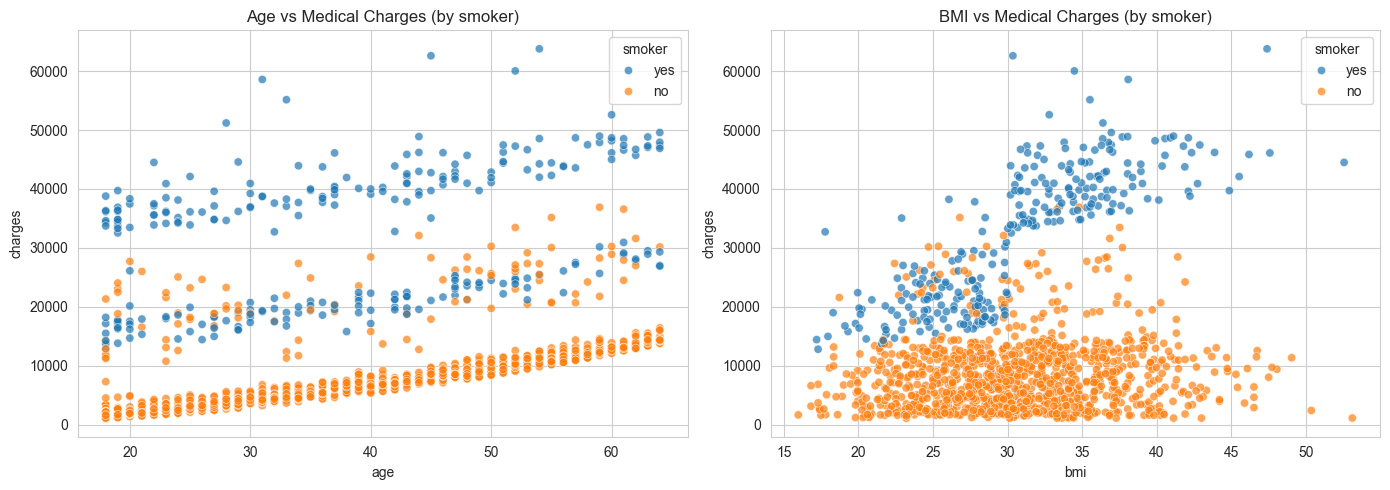

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[0])
axes[0].set_title('Age vs Medical Charges (by smoker)')

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[1])
axes[1].set_title('BMI vs Medical Charges (by smoker)')

plt.tight_layout()
plt.show()

**Observation:** charges rise with **age** in three visible bands — non-smokers (bottom), a mixed middle band, and smokers (top).
For **BMI**, smokers with BMI above ~30 form a distinct high-cost group, while for non-smokers BMI has little effect.

### 10b. Box plot

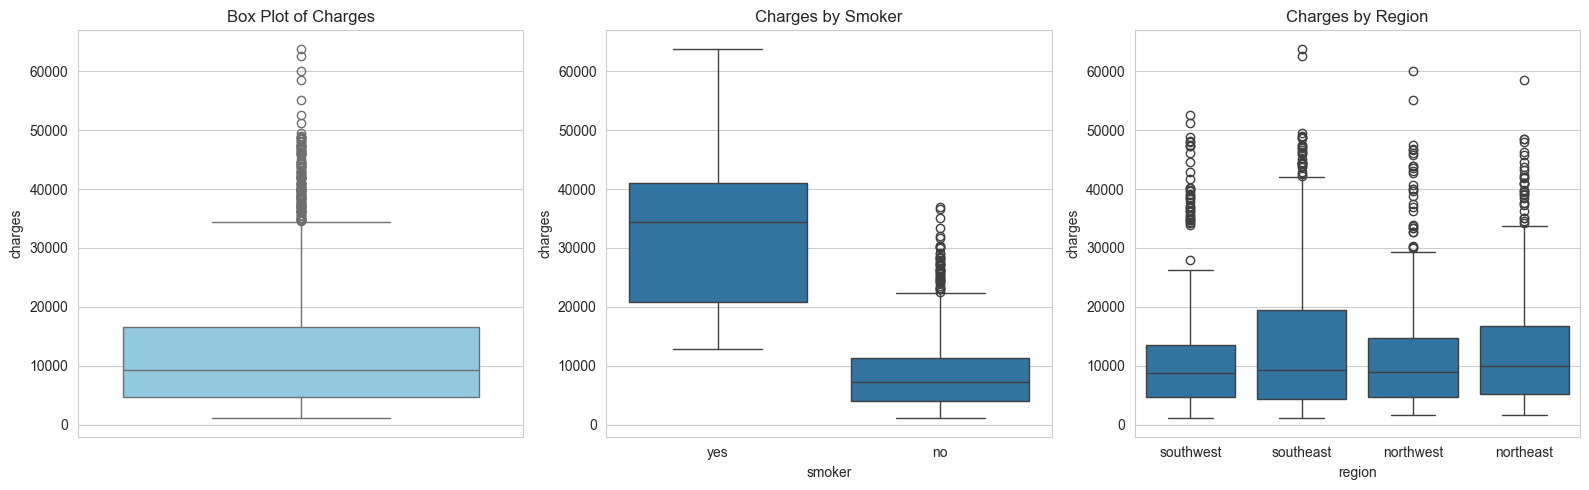

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=df['charges'], ax=axes[0], color='skyblue')
axes[0].set_title('Box Plot of Charges')

sns.boxplot(data=df, x='smoker', y='charges', ax=axes[1])
axes[1].set_title('Charges by Smoker')

sns.boxplot(data=df, x='region', y='charges', ax=axes[2])
axes[2].set_title('Charges by Region')

plt.tight_layout()
plt.show()

**Observation:** the overall box plot shows many outliers above the upper whisker. Smokers have a much higher median and spread than non-smokers;
differences between regions are small.

### 10c. Histogram

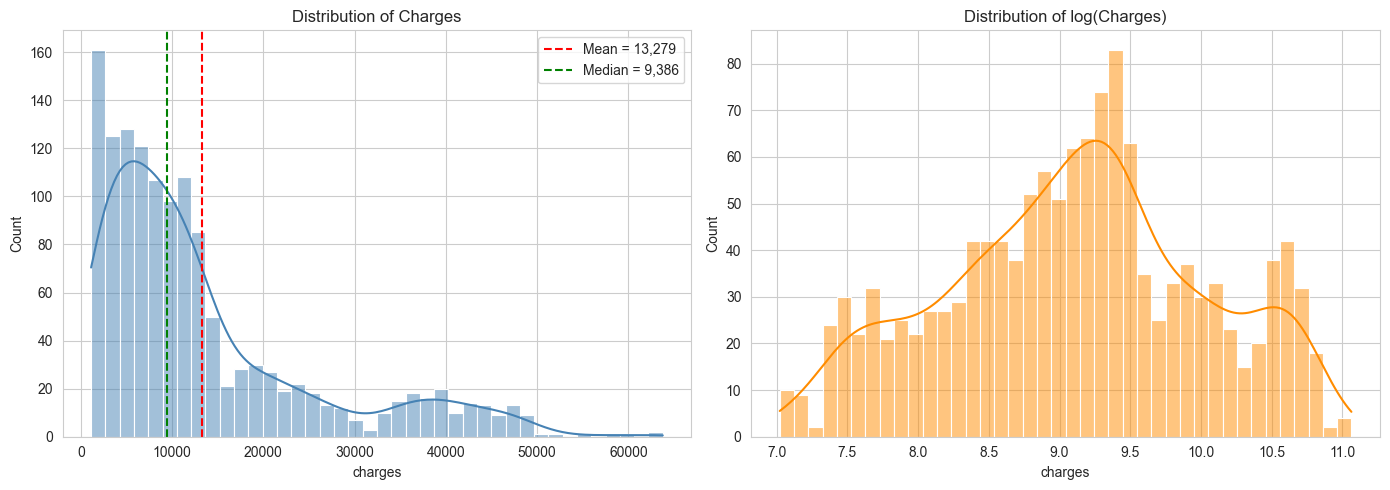

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['charges'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(df['charges'].mean(), color='red', linestyle='--', label=f"Mean = {df['charges'].mean():,.0f}")
axes[0].axvline(df['charges'].median(), color='green', linestyle='--', label=f"Median = {df['charges'].median():,.0f}")
axes[0].set_title('Distribution of Charges')
axes[0].legend()

sns.histplot(np.log(df['charges']), bins=40, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribution of log(Charges)')

plt.tight_layout()
plt.show()

**Observation:** the histogram confirms a **right-skewed** distribution (mean > median). The log-transformed version is much closer to a bell shape.

### 10d. Heat map (correlation matrix)

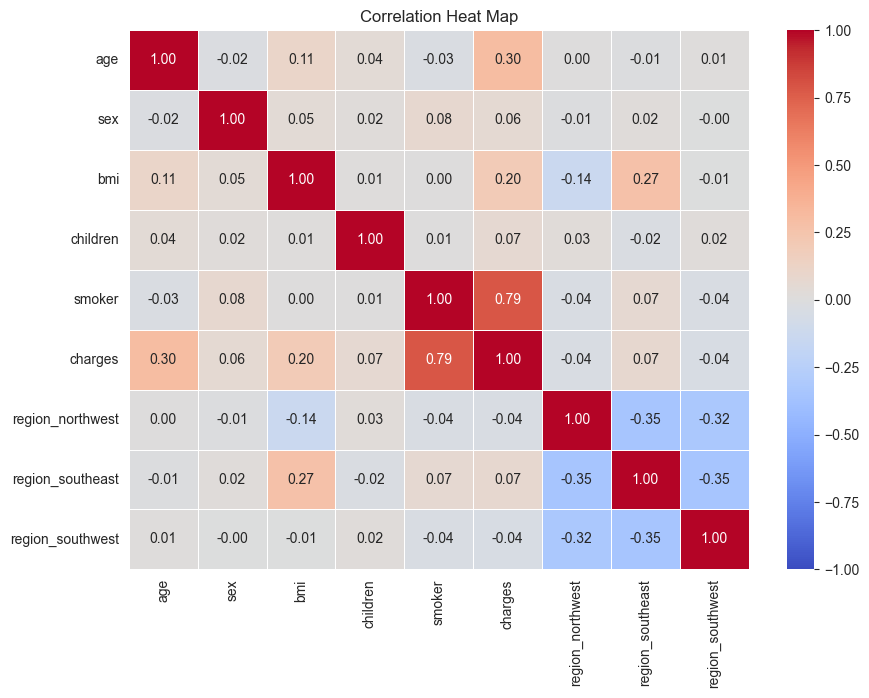

Correlation of each variable with charges:
smoker              0.7870
age                 0.2980
bmi                 0.1980
region_southeast    0.0740
children            0.0670
sex                 0.0580
region_northwest   -0.0390
region_southwest   -0.0440
Name: charges, dtype: float64


In [16]:
# Encode the categorical variables numerically so they can be included in the correlation matrix
df_encoded = df.copy()
df_encoded['sex'] = df_encoded['sex'].map({'female': 0, 'male': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})
df_encoded = pd.get_dummies(df_encoded, columns=['region'], drop_first=True, dtype=int)

corr = df_encoded.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heat Map')
plt.show()

print('Correlation of each variable with charges:')
print(corr['charges'].drop('charges').sort_values(ascending=False).round(3))

**Observation:** `smoker` has the strongest correlation with `charges`, followed by `age` and `bmi`. `sex`, `children` and region have weak correlations.

## Task 11: Hypothesis tests for correlation
Chosen independent variables: **`age`** (numerical) for Pearson & Spearman, and **`smoker`** (categorical) for Chi-square. Significance level **α = 0.05**.

### 11a. Pearson correlation (age vs charges) — linear relationship
- **H₀:** There is no linear correlation between age and charges (ρ = 0).
- **H₁:** There is a significant linear correlation between age and charges (ρ ≠ 0).

In [17]:
alpha = 0.05

r, p_pearson = stats.pearsonr(df['age'], df['charges'])
print(f'Pearson r = {r:.4f}, p-value = {p_pearson:.4e}')
if p_pearson < alpha:
    print('Reject H0 -> there is a statistically significant linear correlation between age and charges.')
else:
    print('Fail to reject H0 -> no significant linear correlation between age and charges.')

Pearson r = 0.2983, p-value = 6.9757e-29
Reject H0 -> there is a statistically significant linear correlation between age and charges.


### 11b. Spearman rank correlation (age vs charges) — monotonic relationship
Spearman does not assume normality, which suits the skewed `charges` variable.
- **H₀:** There is no monotonic correlation between age and charges.
- **H₁:** There is a significant monotonic correlation between age and charges.

In [18]:
rho, p_spearman = stats.spearmanr(df['age'], df['charges'])
print(f'Spearman rho = {rho:.4f}, p-value = {p_spearman:.4e}')
if p_spearman < alpha:
    print('Reject H0 -> there is a statistically significant monotonic correlation between age and charges.')
else:
    print('Fail to reject H0 -> no significant monotonic correlation between age and charges.')

Spearman rho = 0.5335, p-value = 3.1878e-99
Reject H0 -> there is a statistically significant monotonic correlation between age and charges.


### 11c. Chi-square test of independence (smoker vs charges category)
Chi-square needs two categorical variables, so `charges` is grouped into **Low** (≤ median) and **High** (> median).
- **H₀:** Smoking status and charge level are independent.
- **H₁:** Smoking status and charge level are associated (dependent).

In [19]:
df['charges_level'] = np.where(df['charges'] > df['charges'].median(), 'High', 'Low')

contingency = pd.crosstab(df['smoker'], df['charges_level'])
print('Contingency table (observed):')
display(contingency)

chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print('Expected frequencies:')
display(pd.DataFrame(expected, index=contingency.index, columns=contingency.columns).round(2))
print(f'Chi-square = {chi2:.4f}, degrees of freedom = {dof}, p-value = {p_chi:.4e}')
if p_chi < alpha:
    print('Reject H0 -> smoking status and charge level are significantly associated.')
else:
    print('Fail to reject H0 -> no significant association between smoking status and charge level.')

Contingency table (observed):


charges_level,High,Low
smoker,,
no,394,669
yes,274,0


Expected frequencies:


charges_level,High,Low
smoker,,
no,531.1000,531.9000
yes,136.9000,137.1000


Chi-square = 342.6296, degrees of freedom = 1, p-value = 1.7068e-76
Reject H0 -> smoking status and charge level are significantly associated.


In [20]:
# Summary of the correlation tests
pd.DataFrame({
    'Test': ['Pearson', 'Spearman', 'Chi-square'],
    'Variables': ['age vs charges', 'age vs charges', 'smoker vs charges_level'],
    'Statistic': [r, rho, chi2],
    'p-value': [p_pearson, p_spearman, p_chi],
    'Decision (α=0.05)': ['Reject H0' if p < alpha else 'Fail to reject H0'
                          for p in [p_pearson, p_spearman, p_chi]]
})

,Test,Variables,Statistic,p-value,Decision (α=0.05)
0,Pearson,age vs charges,0.2983,0.0000,Reject H0
1,Spearman,age vs charges,0.5335,0.0000,Reject H0
2,Chi-square,smoker vs charges_level,342.6296,0.0000,Reject H0


## Task 12: One-sample t-test — is the sample representative of the population?
We compare the **mean charges of the random sample (n = 150)** with the **population mean**.
- **H₀:** The sample mean equals the population mean (μ_sample = μ_population) → the sample is representative.
- **H₁:** The sample mean is different from the population mean → the sample is not representative.

In [21]:
population_mean = df['charges'].mean()

t_stat, p_t = stats.ttest_1samp(random_sample['charges'], popmean=population_mean)
print(f'Population mean charges : {population_mean:,.2f}')
print(f'Random sample mean      : {random_sample["charges"].mean():,.2f}')
print(f't-statistic = {t_stat:.4f}, p-value = {p_t:.4f}')
if p_t < alpha:
    print('Reject H0 -> the random sample mean differs significantly; the sample is NOT representative.')
else:
    print('Fail to reject H0 -> no significant difference; the random sample IS representative of the population.')

Population mean charges : 13,279.12
Random sample mean      : 13,960.71
t-statistic = 0.6126, p-value = 0.5411
Fail to reject H0 -> no significant difference; the random sample IS representative of the population.


In [22]:
# Same test on the systematic sample (drawn from a filtered sub-group) for comparison
t_sys, p_sys = stats.ttest_1samp(systematic['charges'], popmean=population_mean)
print(f'Systematic sample mean : {systematic["charges"].mean():,.2f}')
print(f't-statistic = {t_sys:.4f}, p-value = {p_sys:.4f}')
print('Reject H0 -> not representative of the whole population' if p_sys < alpha
      else 'Fail to reject H0 -> representative of the whole population')

Systematic sample mean : 14,225.54
t-statistic = 0.9718, p-value = 0.3327
Fail to reject H0 -> representative of the whole population


In [23]:
# 95% confidence interval for the random-sample mean
ci = stats.t.interval(0.95, df=len(random_sample) - 1,
                      loc=random_sample['charges'].mean(),
                      scale=stats.sem(random_sample['charges']))
print(f'95% CI for mean charges (random sample): {ci[0]:,.2f} to {ci[1]:,.2f}')
print('Population mean inside the CI:', ci[0] <= population_mean <= ci[1])

95% CI for mean charges (random sample): 11,762.00 to 16,159.42
Population mean inside the CI: True


**Note on assumptions:** the t-test assumes the sample mean is approximately normally distributed. Although `charges` is skewed,
with n = 150 the **Central Limit Theorem** makes the sampling distribution of the mean approximately normal, so the t-test is valid.

---
## Conclusion (Deliverable 1)
- `charges` (dependent variable) is right-skewed with high variability and genuine high-value outliers, mostly smokers.
- `smoker`, `age` and `bmi` are the variables most related to charges; correlation and chi-square tests confirm significant relationships.
- The random sample of 150 records is representative of the population (one-sample t-test), so sample-based conclusions can be generalised.
- These findings prepare the data for the regression, classification and clustering models in Deliverable 2.